# Employee Attrition Prediction with Scikit-learn

**Assignment:** Employee Attrition Prediction with Scikit-learn  
**Dataset supplied:** `WA_Fn-UseC_-HR-Employee-Attrition_16112026.csv`

> **File-format note:** The assignment document mentions reading an Excel workbook with `pd.read_excel()`. The supplied dataset is a CSV file, so this notebook correctly uses `pd.read_csv()`.

This notebook completes all eight tasks using the seven specified input features. It uses a stratified 80/20 train-test split, training-only preprocessing inside a scikit-learn pipeline, a most-frequent baseline, and an `MLPClassifier` neural network.

**Target definition:** `Attrition = Yes` is the positive class (encoded as `1`); `Attrition = No` is encoded as `0`.

## Setup and imports

In [7]:
import warnings
warnings.filterwarnings("ignore", category=UserWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, ConfusionMatrixDisplay
)
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

RANDOM_STATE = 42
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 120)

## Task 1 — Load and inspect the employee records

In [8]:
# The uploaded file is CSV (not Excel), therefore read_csv is used.
df = pd.read_csv("WA_Fn-UseC_-HR-Employee-Attrition_16112026.csv")

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (1470, 35)


,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,EnvironmentSatisfaction,Gender,HourlyRate,JobInvolvement,JobLevel,JobRole,JobSatisfaction,MaritalStatus,MonthlyIncome,MonthlyRate,NumCompaniesWorked,Over18,OverTime,PercentSalaryHike,PerformanceRating,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,2,Female,94,3,2,Sales Executive,4,Single,5993,19479,8,Y,Yes,11,3,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,3,Male,61,2,2,Research Scientist,2,Married,5130,24907,1,Y,No,23,4,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,4,Male,92,2,1,Laboratory Technician,3,Single,2090,2396,6,Y,Yes,15,3,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,4,Female,56,3,1,Research Scientist,3,Married,2909,23159,1,Y,Yes,11,3,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,1,Male,40,3,1,Laboratory Technician,2,Married,3468,16632,9,Y,No,12,3,4,80,1,6,3,3,2,2,2,2


In [9]:
numeric_features = [
    "Age", "DistanceFromHome", "MonthlyIncome",
    "YearsAtCompany", "JobSatisfaction"
]
categorical_features = ["Department", "OverTime"]
target_col = "Attrition"
required_columns = numeric_features + categorical_features + [target_col]

# Validate that the requested columns are present.
missing_columns = [col for col in required_columns if col not in df.columns]
if missing_columns:
    raise ValueError(f"Required columns missing from dataset: {missing_columns}")

inspection = pd.DataFrame({
    "data_type": df[required_columns].dtypes.astype(str),
    "missing_values": df[required_columns].isna().sum()
})
display(inspection)

,data_type,missing_values
Age,int64,0
DistanceFromHome,int64,0
MonthlyIncome,int64,0
YearsAtCompany,int64,0
JobSatisfaction,int64,0
Department,object,0
OverTime,object,0
Attrition,object,0


In [10]:
# Count missing and out-of-domain target values before excluding them.
valid_target_values = ["Yes", "No"]
missing_target_count = int(df[target_col].isna().sum())
out_of_domain_target_count = int((~df[target_col].isin(valid_target_values) & df[target_col].notna()).sum())

print("Missing target values:", missing_target_count)
print("Out-of-domain target values:", out_of_domain_target_count)

# Keep only rows with a valid Yes/No target.
data = df.loc[df[target_col].isin(valid_target_values), required_columns].copy()
data[target_col] = data[target_col].map({"No": 0, "Yes": 1}).astype(int)

print("Rows before target validation:", len(df))
print("Rows retained for modelling:", len(data))
print("Rows excluded:", len(df) - len(data))
display(data.head())

Missing target values: 0
Out-of-domain target values: 0
Rows before target validation: 1470
Rows retained for modelling: 1470
Rows excluded: 0


,Age,DistanceFromHome,MonthlyIncome,YearsAtCompany,JobSatisfaction,Department,OverTime,Attrition
0,41,1,5993,6,4,Sales,Yes,1
1,49,8,5130,10,2,Research & Development,No,0
2,37,2,2090,0,3,Research & Development,Yes,1
3,33,3,2909,8,3,Research & Development,Yes,0
4,27,2,3468,2,2,Research & Development,No,0


**Interpretation**

- Each row represents one employee record.
- The model uses exactly five numerical inputs (`Age`, `DistanceFromHome`, `MonthlyIncome`, `YearsAtCompany`, `JobSatisfaction`) and two categorical inputs (`Department`, `OverTime`).
- `Attrition` is the outcome to predict, so it is not included in the input features.
- `EmployeeNumber` is an identifier rather than a meaningful model input, so it is excluded. Other columns are also excluded because the assignment specifies these seven predictors.
- The supplied dataset contains 35 columns; the modelling table is deliberately restricted to the seven specified predictors and the target.

## Task 2 — Examine attrition prevalence

In [11]:
class_counts = data[target_col].value_counts().reindex([0, 1], fill_value=0)
class_percentages = (class_counts / len(data) * 100).round(2)
prevalence_table = pd.DataFrame({
    "Attrition": ["No", "Yes"],
    "Count": [class_counts.loc[0], class_counts.loc[1]],
    "Percentage": [class_percentages.loc[0], class_percentages.loc[1]]
})
display(prevalence_table)

observed_attrition_rate = float((data[target_col] == 1).mean())
print(f"Overall observed attrition rate: {observed_attrition_rate:.2%}")

,Attrition,Count,Percentage
0,No,1233,83.88
1,Yes,237,16.12


Overall observed attrition rate: 16.12%


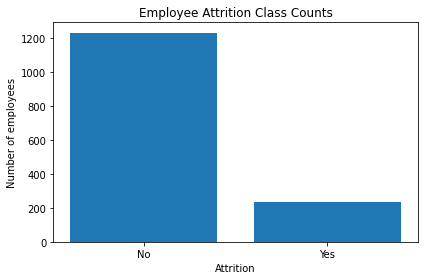

In [12]:
plt.figure(figsize=(6, 4))
plt.bar(["No", "Yes"], [class_counts.loc[0], class_counts.loc[1]])
plt.title("Employee Attrition Class Counts")
plt.xlabel("Attrition")
plt.ylabel("Number of employees")
plt.tight_layout()
plt.show()

In [13]:
overtime_summary = (
    data.assign(OverTime=data["OverTime"].astype(str))
        .groupby("OverTime")[target_col]
        .agg(employees="size", attrition_count="sum", attrition_rate="mean")
        .reset_index()
)
overtime_summary["attrition_rate_pct"] = (overtime_summary["attrition_rate"] * 100).round(2)
display(overtime_summary[["OverTime", "employees", "attrition_count", "attrition_rate_pct"]])

rates = overtime_summary.set_index("OverTime")["attrition_rate"]
if "Yes" in rates.index and "No" in rates.index:
    overtime_difference_pp = (rates["Yes"] - rates["No"]) * 100
    print(f"Attrition-rate difference (OverTime Yes minus No): {overtime_difference_pp:.2f} percentage points")

,OverTime,employees,attrition_count,attrition_rate_pct
0,No,1054,110,10.44
1,Yes,416,127,30.53


Attrition-rate difference (OverTime Yes minus No): 20.09 percentage points


**Interpretation**

The overall attrition rate is the percentage of valid employee records whose target is `Yes`. The overtime comparison reports the number of employees and attrition rate separately for `OverTime = Yes` and `OverTime = No`.

A difference in these observed rates is an association in this dataset; it does **not** establish that overtime causes employees to leave. Other employee and workplace factors may also be involved.

## Task 3 — Create the training and test sets

In [14]:
X = data[numeric_features + categorical_features].copy()
y = data[target_col].copy()

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

split_summary = pd.DataFrame({
    "records": [len(X_train), len(X_test)],
    "attrition_yes_count": [int(y_train.sum()), int(y_test.sum())],
    "attrition_yes_rate_pct": [y_train.mean() * 100, y_test.mean() * 100]
}, index=["Training set", "Test set"]).round(2)
display(split_summary)

,records,attrition_yes_count,attrition_yes_rate_pct
Training set,1176,190,16.16
Test set,294,47,15.99


**Interpretation**

The dataset is split into 80% training records and 20% test records. `stratify=y` preserves approximately the same proportion of `Yes` and `No` outcomes in both sets. `random_state=42` makes the split reproducible. The test set is held out for the final model evaluation.

## Task 4 — Build the preprocessing pipeline

In [15]:
numeric_preprocessor = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_preprocessor = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_preprocessor, numeric_features),
    ("cat", categorical_preprocessor, categorical_features)
])

print("Preprocessing pipeline created.")

Preprocessing pipeline created.


**Interpretation**

- Numerical missing values are replaced with the median learned from the training data, then numerical features are standardised. Scaling is important because `MonthlyIncome` has a much larger numeric range than inputs such as `JobSatisfaction`; without scaling, large-valued features can dominate the neural network's optimisation.
- Categorical missing values are replaced with the most frequent training value, and categories are converted into one-hot encoded columns.
- `handle_unknown="ignore"` allows the pipeline to process a category not seen during training without failing.
- The preprocessing is part of each model pipeline, so imputation, scaling, and category encoding are fitted on training data only. This helps prevent data leakage.

## Task 5 — Train the baseline and neural network

In [16]:
baseline_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", DummyClassifier(strategy="most_frequent"))
])

neural_network = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", MLPClassifier(
        hidden_layer_sizes=(16,),
        max_iter=500,
        random_state=RANDOM_STATE
    ))
])

baseline_model.fit(X_train, y_train)
neural_network.fit(X_train, y_train)

baseline_predictions = baseline_model.predict(X_test)
nn_predictions = neural_network.predict(X_test)

print("Baseline and neural network training completed.")
print("Neural network hidden layers:", 1)
print("Neurons in hidden layer:", 16)

Baseline and neural network training completed.
Neural network hidden layers: 1
Neurons in hidden layer: 16


**Interpretation**

The baseline always predicts the most frequent class in the training data. It provides a simple reference point. The neural network is an `MLPClassifier` with one hidden layer containing 16 neurons, a maximum of 500 training iterations, and `random_state=42` for reproducibility.

## Task 6 — Evaluate model performance

In [17]:
def calculate_metrics(y_true, y_pred, model_name):
    return {
        "Model": model_name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision (Yes)": precision_score(y_true, y_pred, pos_label=1, zero_division=0),
        "Recall (Yes)": recall_score(y_true, y_pred, pos_label=1, zero_division=0),
        "F1-score (Yes)": f1_score(y_true, y_pred, pos_label=1, zero_division=0)
    }

results = pd.DataFrame([
    calculate_metrics(y_test, baseline_predictions, "Most-frequent baseline"),
    calculate_metrics(y_test, nn_predictions, "Neural network (MLP)")
]).set_index("Model")
display(results.round(4))

,Accuracy,Precision (Yes),Recall (Yes),F1-score (Yes)
Model,,,,
Most-frequent baseline,0.8401,0.0000,0.0000,0.0000
Neural network (MLP),0.8469,0.5455,0.2553,0.3478


Neural network confusion matrix (rows = actual, columns = predicted):
[[237  10]
 [ 35  12]]
True negatives (TN): 237
False positives (FP): 10
False negatives (FN): 35
True positives (TP): 12
Actual leavers in test set: 47
Actual leavers correctly identified (TP): 12
Actual leavers missed (FN): 35
Recall calculated from counts: 0.2553


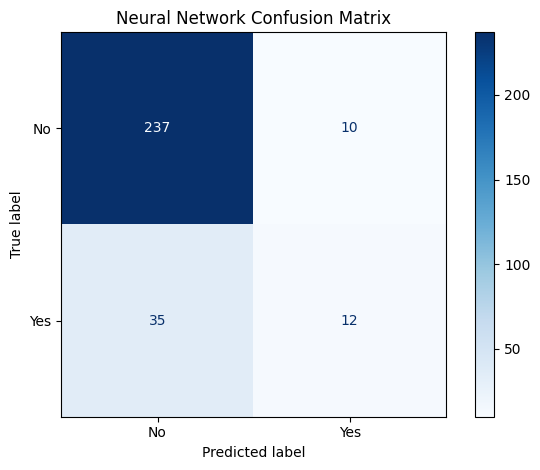

In [12]:
cm = confusion_matrix(y_test, nn_predictions, labels=[0, 1])
tn, fp, fn, tp = cm.ravel()

print("Neural network confusion matrix (rows = actual, columns = predicted):")
print(cm)
print(f"True negatives (TN): {tn}")
print(f"False positives (FP): {fp}")
print(f"False negatives (FN): {fn}")
print(f"True positives (TP): {tp}")

actual_leavers = int((y_test == 1).sum())
print(f"Actual leavers in test set: {actual_leavers}")
print(f"Actual leavers correctly identified (TP): {tp}")
print(f"Actual leavers missed (FN): {fn}")
print(f"Recall calculated from counts: {tp / (tp + fn) if (tp + fn) else 0:.4f}")

disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["No", "Yes"])
disp.plot(cmap="Blues", values_format="d")
plt.title("Neural Network Confusion Matrix")
plt.tight_layout()
plt.show()

**How to interpret the confusion matrix**

- **TP:** An employee actually left and the model predicted `Yes`.
- **FN:** An employee actually left but the model predicted `No` — a missed departure.
- **TN:** An employee stayed and the model predicted `No`.
- **FP:** An employee stayed but the model predicted `Yes` — an unnecessary follow-up if the prediction were used to trigger a review.

Recall for the positive class is `TP / (TP + FN)`. For an HR early-warning use case, recall matters because a false negative is an employee departure the model failed to flag. Compare the neural network's recall with the baseline's recall; the baseline may have zero recall if it predicts only `No`. A higher recall can be useful, but it should be considered alongside precision and the number of false positives.

## Task 7 — Inspect individual predictions

In [18]:
# Probability of Attrition=Yes. Locate class 1 explicitly rather than assuming column order.
class_labels = list(neural_network.classes_)
positive_class_index = class_labels.index(1)
attrition_probabilities = neural_network.predict_proba(X_test)[:, positive_class_index]

prediction_details = X_test.copy().reset_index(drop=True)
prediction_details["Actual"] = y_test.reset_index(drop=True).map({0: "No", 1: "Yes"})
prediction_details["Predicted"] = pd.Series(nn_predictions).map({0: "No", 1: "Yes"})
prediction_details["Probability_Attrition_Yes"] = attrition_probabilities

false_negatives = prediction_details[
    (prediction_details["Actual"] == "Yes") &
    (prediction_details["Predicted"] == "No")
]
false_positives = prediction_details[
    (prediction_details["Actual"] == "No") &
    (prediction_details["Predicted"] == "Yes")
]

display_columns = [
    "Actual", "Predicted", "Probability_Attrition_Yes",
    "Age", "MonthlyIncome", "YearsAtCompany", "OverTime", "Department"
]

print("Up to three false negatives (actual Yes, predicted No):")
display(false_negatives[display_columns].head(3))

print("Up to three false positives (actual No, predicted Yes):")
display(false_positives[display_columns].head(3))

Up to three false negatives (actual Yes, predicted No):


,Actual,Predicted,Probability_Attrition_Yes,Age,MonthlyIncome,YearsAtCompany,OverTime,Department
4,Yes,No,0.464827,36,3388,1,Yes,Research & Development
21,Yes,No,0.172936,31,6179,10,Yes,Research & Development
27,Yes,No,0.025380,51,10650,4,No,Research & Development


Up to three false positives (actual No, predicted Yes):


,Actual,Predicted,Probability_Attrition_Yes,Age,MonthlyIncome,YearsAtCompany,OverTime,Department
0,No,Yes,0.702308,24,2033,1,No,Sales
9,No,Yes,0.546645,18,1514,0,No,Research & Development
15,No,Yes,0.548307,27,2478,4,Yes,Research & Development


In [22]:
if len(false_negatives) > 0:
    example = false_negatives.iloc[0]
    print("Example false negative:")
    print(
        f"The employee's actual outcome was {example['Actual']}, but the model predicted "
        f"{example['Predicted']}. The model assigned a {example['Probability_Attrition_Yes']:.1%} "
        f"probability to Attrition=Yes. Selected inputs: Age={example['Age']}, "
        f"MonthlyIncome={example['MonthlyIncome']}, YearsAtCompany={example['YearsAtCompany']}, "
        f"OverTime={example['OverTime']}, Department={example['Department']}."
    )
elif len(false_positives) > 0:
    example = false_positives.iloc[0]
    print("No false negatives were found. Example false positive:")
    print(
        f"The employee stayed (actual No), but the model predicted Yes, with a "
        f"{example['Probability_Attrition_Yes']:.1%} probability of Attrition=Yes. "
        f"Selected inputs: Age={example['Age']}, MonthlyIncome={example['MonthlyIncome']}, "
        f"YearsAtCompany={example['YearsAtCompany']}, OverTime={example['OverTime']}, "
        f"Department={example['Department']}."
    )
else:
    print("No false negatives or false positives were found in this test set; inspect correct predictions instead.")

Example false negative:
The employee's actual outcome was Yes, but the model predicted No. The model assigned a 46.5% probability to Attrition=Yes. Selected inputs: Age=36, MonthlyIncome=3388, YearsAtCompany=1, OverTime=Yes, Department=Research & Development.


**Interpretation**

False negatives are especially important to inspect because they are actual departures that were not flagged by the model. False positives are employees flagged by the model who did not leave in the test data. The probability column is the model's estimated probability for `Attrition = Yes`; it is not a guarantee that an employee will leave.

Only a small sample of errors is displayed. The selected input fields provide context for review, but they do not explain why an individual employee left or stayed.

## Task 8 — HR recommendation

In [24]:
from sklearn.metrics import recall_score, confusion_matrix

nn_recall = recall_score(
    y_test, nn_predictions, pos_label=1, zero_division=0
)

baseline_recall = recall_score(
    y_test, baseline_predictions, pos_label=1, zero_division=0
)

# Calculate confusion matrix
tn, fp, fn, tp = confusion_matrix(
    y_test, nn_predictions, labels=[0, 1]
).ravel()

# Number of actual departures missed
missed_departures = int(fn)

print(f"Observed attrition rate in the full valid dataset: {observed_attrition_rate:.2%}")
print(f"Baseline recall for Attrition=Yes: {baseline_recall:.2%}")
print(f"Neural network recall for Attrition=Yes: {nn_recall:.2%}")
print(f"Actual departures missed by the neural network in the test set: {missed_departures}")

Observed attrition rate in the full valid dataset: 16.12%
Baseline recall for Attrition=Yes: 0.00%
Neural network recall for Attrition=Yes: 25.53%
Actual departures missed by the neural network in the test set: 35


### Recommendation

Use the neural network, if its measured performance is acceptable to HR, only as a **decision-support signal** to prioritise voluntary, confidential employee check-ins — not as an automated decision-maker. HR should review flagged cases with appropriate context and offer support rather than treating a prediction as a fact.

Before relying on this model, HR should collect and evaluate additional relevant evidence, validate performance on newer data and across departments and employee groups, check for bias and privacy risks, calibrate the probability threshold to the cost of missed departures versus unnecessary follow-ups, and monitor performance over time. The model uses only seven features and cannot capture all reasons an employee may leave. Predictions must not be used alone for hiring, promotion, compensation, disciplinary action, or termination decisions.